# Boston House Price Prediction
**ShadowFox — Beginner Machine Learning Task**  
**Author:** Shreeraj Singh Bais

## Objective
Predict the historical Boston Housing target (`MEDV`) from the features in the dataset supplied for this task.

> **Dataset limitation:** `MEDV` is a historical median home value in thousands of US dollars, not today's market price. This classic dataset has known limitations and is used only as an educational exercise, not for real-world valuation, lending, or policy decisions.

## Workflow
Dataset inspection → EDA → preprocessing → model training → evaluation → prediction demonstration.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA = ROOT / "data" / "boston_house_prices.csv"
RESULTS = ROOT / "results"
MODELS_DIR = ROOT / "models"
RESULTS.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True)
print("Project:", ROOT.resolve())

Project: D:\internship\ShadowFox\Boston_House_Price_Prediction\Boston_House_Price_Prediction


## 2. Load and inspect the official supplied dataset

In [2]:
df = pd.read_csv(DATA)
print("Shape:", df.shape)
display(df.head())
print("\\nData types:\\n", df.dtypes)
print("\\nDescriptive statistics:\\n", df.describe().T)
print("\\nMissing values:\\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


\nData types:\n CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX          int64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object
\nDescriptive statistics:\n          count        mean         std        min         25%        50%  \
CRIM     506.0    3.613524    8.601545    0.00632    0.082045    0.25651   
ZN       506.0   11.363636   23.322453    0.00000    0.000000    0.00000   
INDUS    506.0   11.136779    6.860353    0.46000    5.190000    9.69000   
CHAS     506.0    0.069170    0.253994    0.00000    0.000000    0.00000   
NOX      506.0    0.554695    0.115878    0.38500    0.449000    0.53800   
RM       506.0    6.284634    0.702617    3.56100    5.885500    6.20850   
AGE      506.0   68.574901   28.148861    2.90000   45.025000   77.50000   
DIS      506.0    3.795043    2.105710    1.12960    2.100175    3.2

## 3. Exploratory Data Analysis

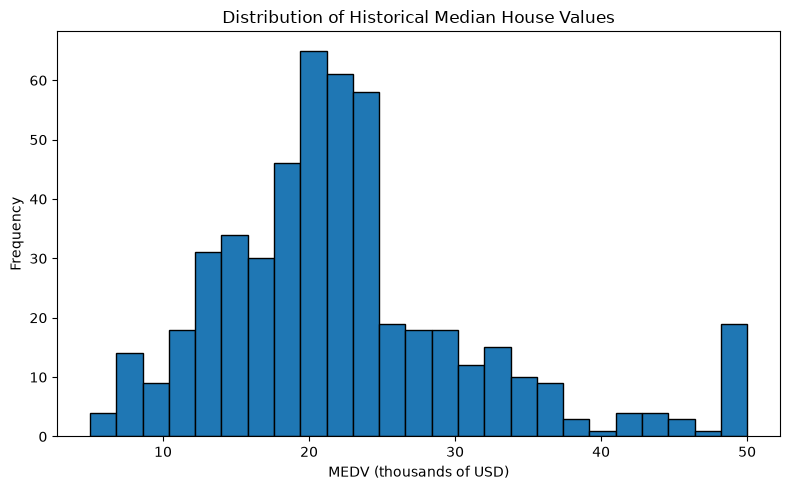

In [3]:
plt.figure(figsize=(8,5))
plt.hist(df["MEDV"], bins=25, edgecolor="black")
plt.title("Distribution of Historical Median House Values")
plt.xlabel("MEDV (thousands of USD)"); plt.ylabel("Frequency")
plt.tight_layout(); plt.savefig(RESULTS/"01_target_distribution.png",dpi=160); plt.show()

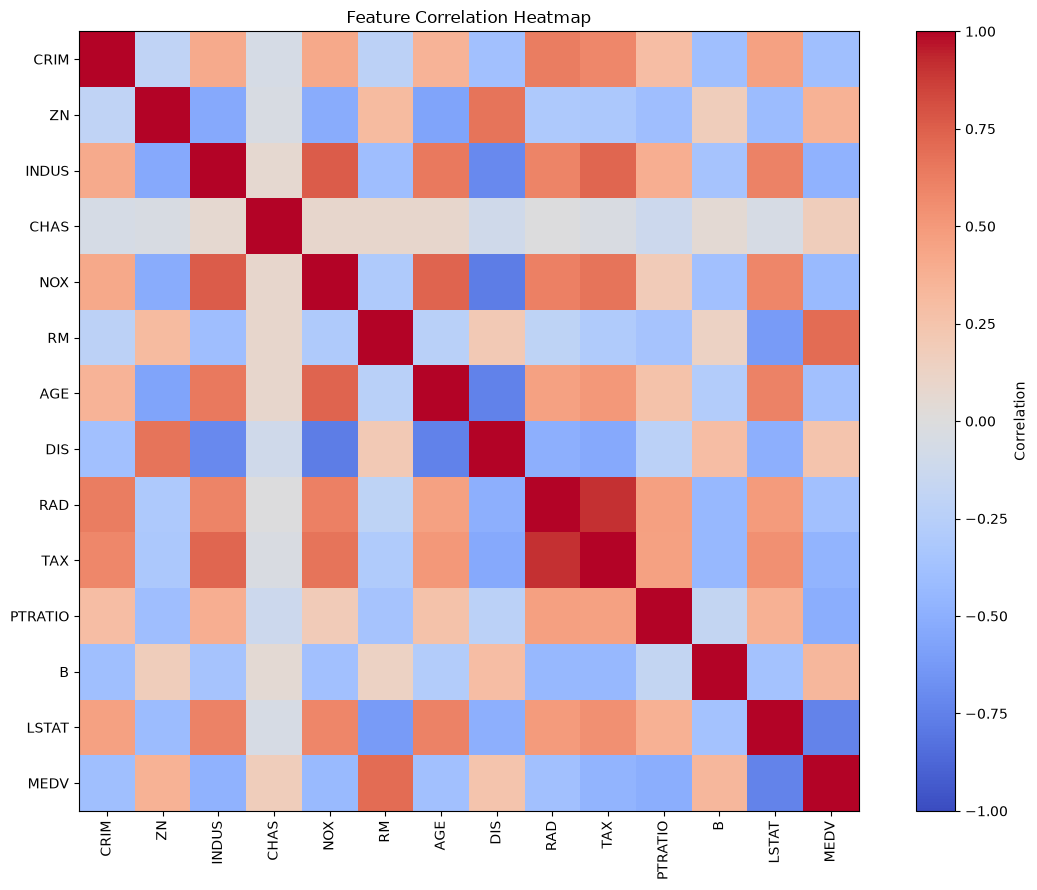

In [4]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12,9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns,rotation=90)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout(); plt.savefig(RESULTS/"02_correlation_heatmap.png",dpi=160); plt.show()

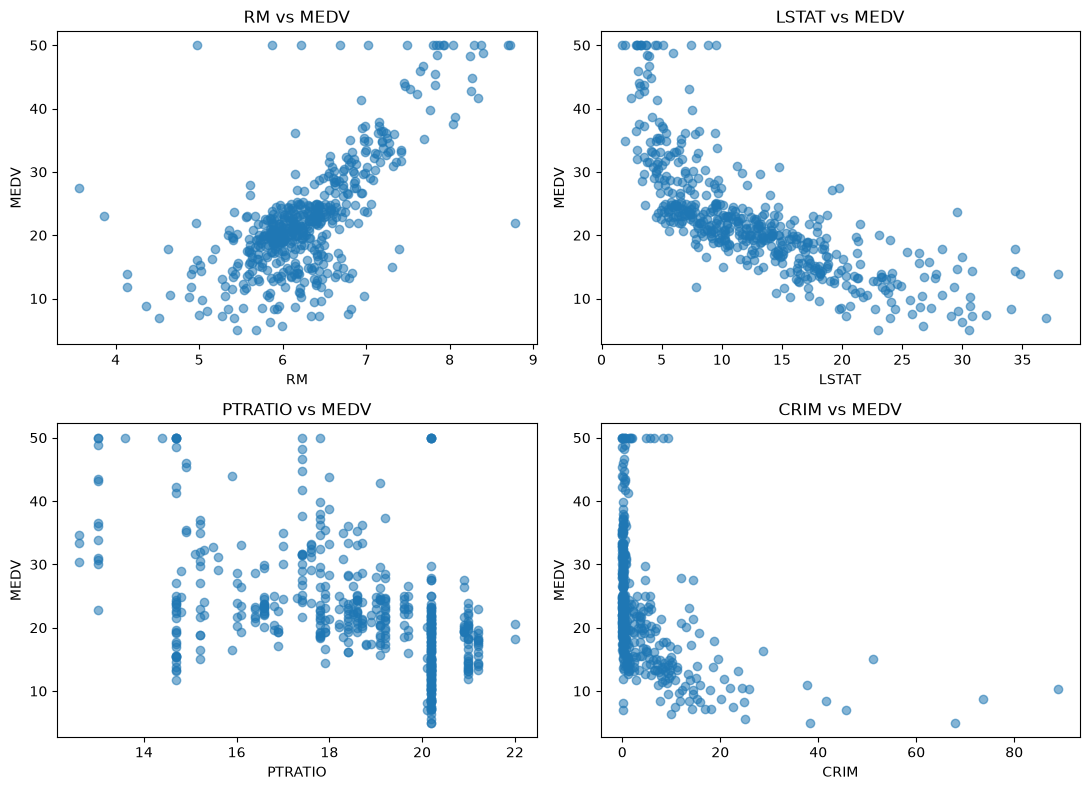

In [5]:
features = ["RM","LSTAT","PTRATIO","CRIM"]
fig, axes = plt.subplots(2,2,figsize=(11,8))
for ax, col in zip(axes.flat,features):
    ax.scatter(df[col],df["MEDV"],alpha=.55)
    ax.set_xlabel(col); ax.set_ylabel("MEDV"); ax.set_title(f"{col} vs MEDV")
plt.tight_layout(); plt.savefig(RESULTS/"03_feature_analysis.png",dpi=160); plt.show()

## 4. Preprocessing and train/test split

In [6]:
X = df.drop(columns="MEDV")
y = df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.20,random_state=42
)
print("Training rows:",len(X_train))
print("Testing rows:",len(X_test))
print("Features:",X.shape[1])

Training rows: 404
Testing rows: 102
Features: 13


## 5. Train and compare regression models

In [7]:
models = {
 "Linear Regression": Pipeline([("scaler",StandardScaler()),("model",LinearRegression())]),
 "Decision Tree": DecisionTreeRegressor(max_depth=5,random_state=42),
 "Random Forest": RandomForestRegressor(n_estimators=300,min_samples_leaf=2,random_state=42),
 "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}
records=[]; fitted={}
for name, model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    fitted[name]=model
    records.append({"Model":name,"MAE":mean_absolute_error(y_test,pred),
                    "MSE":mean_squared_error(y_test,pred),
                    "RMSE":mean_squared_error(y_test,pred)**0.5,
                    "R2":r2_score(y_test,pred)})
comparison=pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True)
display(comparison.round(4))
best_name=comparison.iloc[0]["Model"]
best_model=fitted[best_name]
y_pred=best_model.predict(X_test)
print("Best model by lowest test RMSE:",best_name)

,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,1.9311,6.4099,2.5318,0.9126
1,Decision Tree,2.3082,8.5539,2.9247,0.8834
2,Random Forest,2.1211,9.9996,3.1622,0.8636
3,Linear Regression,3.1891,24.2911,4.9286,0.6688


Best model by lowest test RMSE: Gradient Boosting


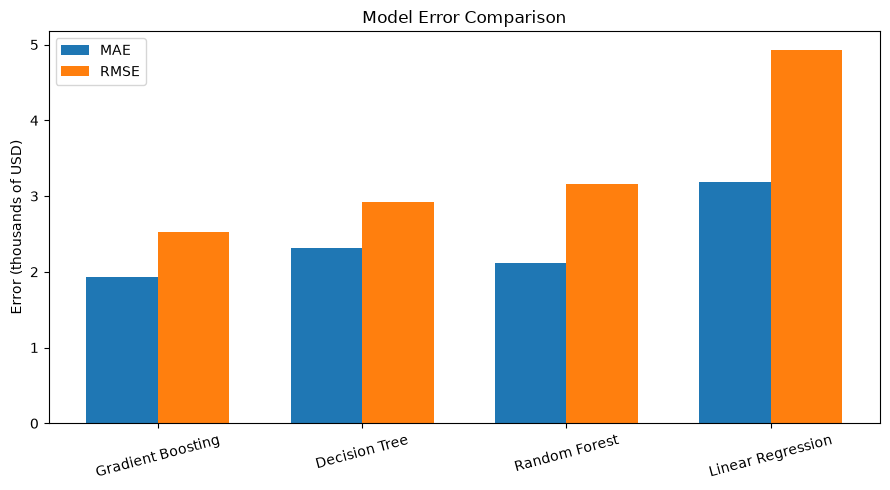

In [8]:
fig, ax=plt.subplots(figsize=(9,5))
x=np.arange(len(comparison)); w=.35
ax.bar(x-w/2,comparison["MAE"],w,label="MAE")
ax.bar(x+w/2,comparison["RMSE"],w,label="RMSE")
ax.set_xticks(x); ax.set_xticklabels(comparison["Model"],rotation=15)
ax.set_ylabel("Error (thousands of USD)"); ax.set_title("Model Error Comparison"); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS/"04_model_comparison.png",dpi=160); plt.show()

## 6. Evaluate the selected model

In [9]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
rmse=mse**0.5
r2=r2_score(y_test,y_pred)
print("Selected model:",best_name)
print(f"MAE : {mae:.4f}")
print(f"MSE : {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2  : {r2:.4f}")

Selected model: Gradient Boosting
MAE : 1.9311
MSE : 6.4099
RMSE: 2.5318
R2  : 0.9126


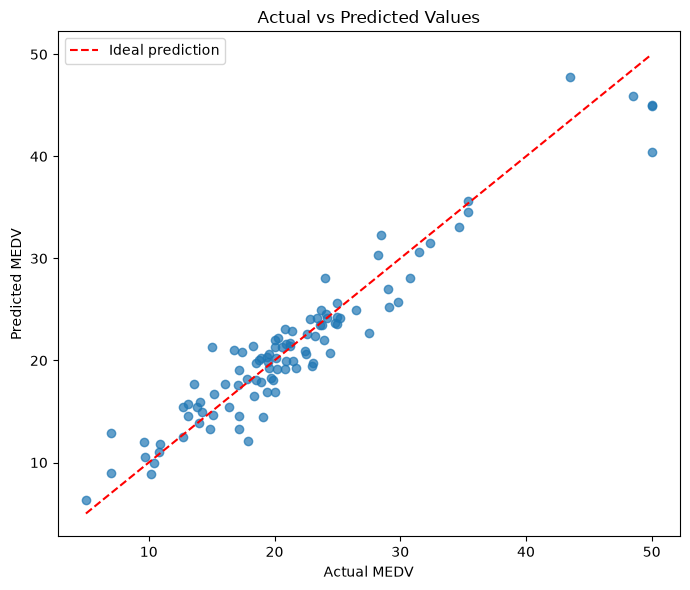

In [10]:
plt.figure(figsize=(7,6))
plt.scatter(y_test,y_pred,alpha=.7)
lo=min(y_test.min(),y_pred.min()); hi=max(y_test.max(),y_pred.max())
plt.plot([lo,hi],[lo,hi],"r--",label="Ideal prediction")
plt.xlabel("Actual MEDV"); plt.ylabel("Predicted MEDV")
plt.title("Actual vs Predicted Values"); plt.legend()
plt.tight_layout(); plt.savefig(RESULTS/"05_actual_vs_predicted.png",dpi=160); plt.show()

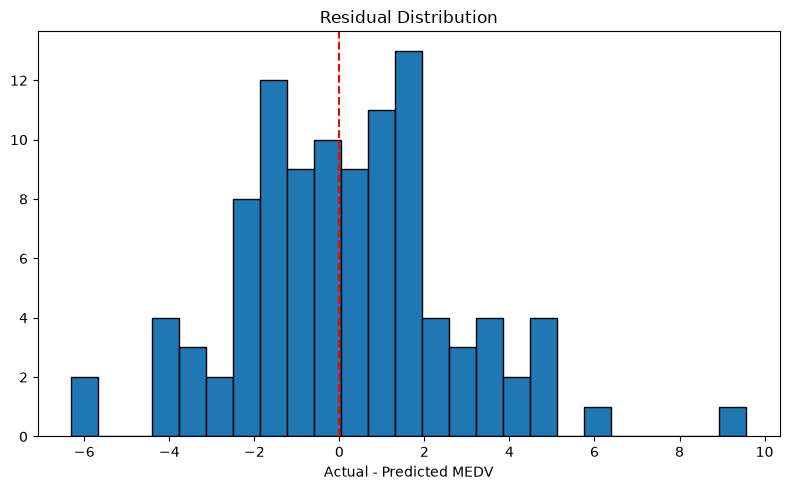

In [11]:
residuals=y_test-y_pred
plt.figure(figsize=(8,5))
plt.hist(residuals,bins=25,edgecolor="black")
plt.axvline(0,color="red",linestyle="--")
plt.title("Residual Distribution"); plt.xlabel("Actual - Predicted MEDV")
plt.tight_layout(); plt.savefig(RESULTS/"06_residual_analysis.png",dpi=160); plt.show()

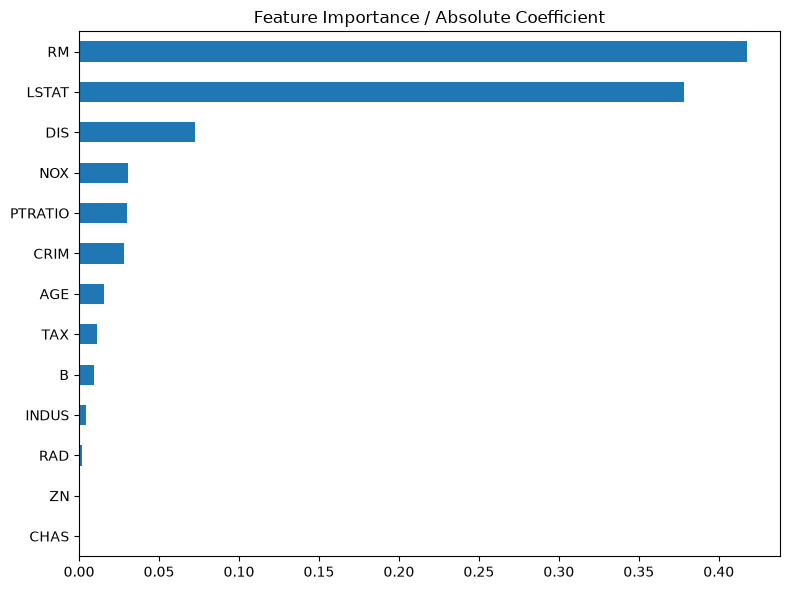

In [12]:
if hasattr(best_model,"feature_importances_"):
    importance=pd.Series(best_model.feature_importances_,index=X.columns).sort_values()
elif hasattr(best_model,"named_steps") and hasattr(best_model.named_steps["model"],"coef_"):
    importance=pd.Series(np.abs(best_model.named_steps["model"].coef_),index=X.columns).sort_values()
else:
    importance=None
if importance is not None:
    plt.figure(figsize=(8,6)); importance.plot(kind="barh")
    plt.title("Feature Importance / Absolute Coefficient")
    plt.tight_layout(); plt.savefig(RESULTS/"07_feature_importance.png",dpi=160); plt.show()

## 7. Prediction demonstration

In [13]:
examples=pd.DataFrame({"Actual_MEDV":y_test.iloc[:10].values,
                       "Predicted_MEDV":y_pred[:10]})
examples["Absolute_Error"]=(examples["Actual_MEDV"]-examples["Predicted_MEDV"]).abs()
display(examples.round(3))

,Actual_MEDV,Predicted_MEDV,Absolute_Error
0,23.6,23.450,0.150
1,32.4,31.461,0.939
2,13.6,17.705,4.105
3,22.8,24.023,1.223
4,16.1,17.681,1.581
5,20.0,22.031,2.031
6,17.8,18.150,0.350
7,14.0,13.830,0.170
8,19.6,20.616,1.016
9,16.8,21.043,4.243


## 8. Save model and results

In [14]:
joblib.dump(best_model,MODELS_DIR/"best_model.joblib")
comparison.to_csv(RESULTS/"model_comparison.csv",index=False)
print("Saved model:",(MODELS_DIR/"best_model.joblib").resolve())
print("Saved model comparison.")

Saved model: D:\internship\ShadowFox\Boston_House_Price_Prediction\Boston_House_Price_Prediction\models\best_model.joblib
Saved model comparison.


## 9. Conclusion
The models were compared using a held-out test set. MAE and RMSE express average prediction error in the target's units; R² summarizes explained variation. The model with the lowest test RMSE was selected. These scores apply only to this historical educational dataset and do not indicate current property-price accuracy.